# A2 — From-scratch NumPy MLP (Fashion-MNIST)

Machine Learning Assessment Task 2.


## Problem Definition
### Research Question:
How does the choice between cross entropy and mean squared error(MSE) affect the learning behaviour of an MLP trained on Fashion-MNIST
### Training Input:
A 28x28 grayscale Fashion MNIST image which is represented by pixels that value 0-255 with each of these images flattened to a dimentional vector of 784.
### Training Target:
An integer label from 0-9 representing each of the 10 clothing classes.
### Model Output:
A 10 dimensional softmax vector representing the model's predicted probability distribution over the ten classes.
### Deployment Output:
The class corresponding to the largest softmax probability is selected utilising argmax.

In [ ]:
import numpy as np
from tensorflow.keras.datasets import fashion_mnist
(X_train_og, Y_train_og), (X_test_og, Y_test_og) = fashion_mnist.load_data() # Load stuff
print(X_train_og.shape) # (60000, 28, 28)
print(Y_train_og.shape) # (60000,) labels
print(X_test_og.shape) # (10000, 28, 28)
print(Y_test_og.shape) # (10000, ) labels


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28)
(60000,)
(10000, 28, 28)
(10000,)


In [ ]:
X_train = X_train_og.reshape(-1, 784)/ 255 # Flatten
X_test = X_test_og.reshape(-1, 784)/ 255 # Flatten
print(X_train.shape)
print(X_test.shape)
print(len(np.unique(Y_train_og))) # Number of classes

(60000, 784)
(10000, 784)
10


In [ ]:
Y_train = Y_train_og.copy()
Y_test = Y_test_og.copy()

indices = np.random.permutation(X_train.shape[0]) # Shuffling the data

X_train = X_train[indices] # Shuffled
Y_train = Y_train[indices] # Shuffled

X_val = X_train[54000:]
Y_val = Y_train[54000:]
X_training = X_train[:54000]
Y_training = Y_train[:54000]

print(X_val.shape)
print(Y_val.shape)
print(X_training.shape)
print(Y_training.shape)

(6000, 784)
(6000,)
(54000, 784)
(54000,)


In [ ]:
def relu(z):
  return np.maximum(0,z) # Between 0-z

def relu_derive(z):
  return (z>0).astype(float) # Same shape as input, z>0

def softmax(z):
  z = z - np.max(z, axis=1, keepdims=True) # z: (64, 10)
  exp = np.exp(z) # exp:(64, 10)
  return exp/np.sum(exp, axis=1, keepdims=True) # Outputs the probabilities of the 10 classes

def one_hot(y, n_classes = 10):
  oh = np.zeros((y.size, n_classes))  # oh:(64, 10) one row per class
  oh[np.arange(y.size), y] = 1 # Put 1 int he columns correct class
  return oh

def cross_entropy_loses(pred, y_true):
  pred = np.clip(pred, 1e-12, 1.0) # Keeps probabilities away from log(0)
  log_likelihood = y_true * np.log(pred) # (64,10) multiply
  return np.mean(-1 * np.sum(log_likelihood, axis=1)) # Return the loss value

def mse_loss(pred, y_true):
  error = pred - y_true
  return np.mean(error ** 2) # Returning the loss

def accuracy(model, X, y):
    preds = np.argmax(model.forward(X), axis=1) # Chooses the highest probability of each row
    return np.mean(preds == y) # Compare predicted labels with true labels

In [ ]:
class MLP:
  def __init__(self, n_input=784, n_hidden1 = 128 ,n_hidden2=64, n_output=10):
    rng = np.random.default_rng(0) # Same random weights each time the model is created aka seed 0
    random_weights_1 = rng.standard_normal((n_input, n_hidden1)) # W1: (784, 128)
    scale_1 = np.sqrt(2.0 / n_input)  # He initialization scale for layer 1
    self.W1 = random_weights_1 * scale_1 # W1:(784, 128)
    self.b1 = np.zeros((1, n_hidden1)) # b1:(1, 128)

    random_weights_2 = rng.standard_normal((n_hidden1, n_hidden2)) # W2:(128, 64)
    scale_2 = np.sqrt(2.0 / n_hidden1) # He initialization scale for layer 2
    self.W2 = random_weights_2 * scale_2 # W2:(128, 64)
    self.b2 = np.zeros((1, n_hidden2)) # b2:(1, 64)

    random_weights_3 = rng.standard_normal((n_hidden2, n_output)) # W3:(64, 10)
    scale_3 = np.sqrt(2.0 / n_hidden2) # He initialization scale for layer 3
    self.W3 = random_weights_3 * scale_3 # W3:(64, 10)
    self.b3 = np.zeros((1, n_output)) # b3:(1, 10)

  def forward(self, X):
    self.Z1 = X @ self.W1 + self.b1 # X:(64, 784), W1: (784, 128), b1:(1, 128)
    self.A1 = relu(self.Z1) #Z1/A1:(64, 128)
    self.Z2 = self.A1 @ self.W2 + self.b2 # A1:(64, 128), W2:(128, 64), b2:(1, 64)
    self.A2 = relu(self.Z2) # Z2/A2:(64, 64)
    self.Z3 = self.A2 @ self.W3 + self.b3 # A2:(64, 64), W3:(64, 10), b3:(1, 10)
    self.A3 = softmax(self.Z3) # Z3/A3:(64, 10)
    return self.A3 # output:(64, 10)

  def backward(self, X, y_true, use_mse = False, lr = 0.01):
    n = X.shape[0] # n = 64
    if use_mse:
      dA3 = 2 * (self.A3 - y_true) / (n * self.A3.shape[1]) # A3:(64, 10), y_true:(64, 10)

      dZ3 = self.A3 * (
          dA3 - np.sum(dA3 * self.A3, axis=1, keepdims=True) # dA3:(64, 10), A3:(64, 10)
      )
    else:
      dZ3 = (self.A3 - y_true)/n # A3:(64, 10), y_true:(64, 10)
    dW3 = self.A2.T @ dZ3 # A2:(64, 64), dZ3:(64, 10)
    db3 = np.sum(dZ3, axis= 0, keepdims= True)  # dZ3:(64, 10)
    dA2 = dZ3 @ self.W3.T # dZ3:(64, 10), W3:(64, 10)
    dZ2 = dA2 * relu_derive(self.Z2)
    dW2 = self.A1.T @ dZ2 # A1:(64, 128), dZ2:(64, 64)
    db2 = np.sum(dZ2, axis = 0, keepdims = True) # dZ2:(64, 64)
    dA1 = dZ2 @ self.W2.T # dZ2:(64, 64), W2: (128, 64)
    dZ1 = dA1 * relu_derive(self.Z1)
    dW1 = X.T @ dZ1 # X:(64, 784), dZ1:(64, 128)
    db1 = np.sum(dZ1, axis = 0, keepdims = True) # dZ1:(64, 128)

    self.W1 -= lr * dW1
    self.b1 -= lr * db1
    self.W2 -= lr * dW2
    self.b2 -= lr * db2
    self.W3 -= lr * dW3
    self.b3 -= lr * db3


# Untrained network
Checking the results of the random weights that have no training yet. This is where I am expecting a result around 15% since the network has learnt anything.

In [ ]:
def train(model, X, y, X_val, y_val, epochs=15, lr=0.01, batch_size=64, use_mse = False):
    y_one_hot = one_hot(y) # y_one_hot:(54000, 10)
    history = [] # Stores results from each epoch

    for epoch in range(epochs):
        for start in range(0, X.shape[0], batch_size): # Start moves through the training data in steps of 64
            end = start + batch_size
            X_batch = X[start:end] # X_batch:(64, 784)
            y_batch = y_one_hot[start:end] # y_batch: (64, 10)
            probs = model.forward(X_batch) # 10 output probabilities for each image
            if use_mse:
              loss = mse_loss(probs, y_batch)
            else:
              loss = cross_entropy_loses(probs, y_batch)
            model.backward(X_batch, y_batch, use_mse=use_mse, lr=lr) # Calculates gradients and updates weights/biases

        train_probs = model.forward(X) # train_probs: (54000, 10)
        if use_mse:
            train_loss = mse_loss(train_probs, y_one_hot)
        else:
            train_loss = cross_entropy_loses(train_probs, y_one_hot)

        train_acc = accuracy(model, X, y) # Prediction for 54000 training images
        val_acc = accuracy(model, X_val, y_val) # X_val: (6000, 784), y_val: (6000,)
        history.append((epoch + 1, train_loss, val_acc)) # Stores epoch number, training loss and validation accuracy
        print(f"Epoch {epoch + 1}, "f"Loss: {train_loss:.4f}, "f"Train Accuracy: {train_acc:.4f}, "f"Validation Accuracy: {val_acc:.4f}")
    return history

ce0 = MLP(n_input=X_training.shape[1]) # X_training.shape[1] = 784
untrained_acc = accuracy(ce0, X_test, Y_test) # Evaluates the randomly initialized model before training
print("Untrained Cross Entropy Model:", untrained_acc)

mse0 = MLP(n_input=X_training.shape[1]) # Creates another randomly initialized MLP with the same architecture
mse_untrained = accuracy(mse0, X_test, Y_test) # Evaluates the randomly initialized model before training
print("Untrained MSE model:", mse_untrained)

Untrained Cross Entropy Model: 0.1646
Untrained MSE model: 0.1646


# Trained Network
Start training the models and comparing the data to see how both their strengths and their weaknesses clearly.

In [ ]:
ce_model = MLP(n_input=X_training.shape[1])
mse_model = MLP(n_input=X_training.shape[1]) # Seed of life
print("\nCross Entropy")
hist_ce = train(ce_model,X_training,Y_training,X_val,Y_val,use_mse=False)
print("\nMSE")
hist_mse = train(mse_model,X_training,Y_training,X_val,Y_val,use_mse=True) # Trains MSE model using the same 54000 training images and 6000 validation images

val_acc = accuracy(ce_model, X_val, Y_val)
test_acc = accuracy(ce_model, X_test, Y_test)
print("\nCross Entropy Validation accuracy:", val_acc)
print("Cross Entropy Test accuracy:", test_acc)

mse_val_acc = accuracy(mse_model, X_val, Y_val)
mse_test_acc = accuracy(mse_model, X_test, Y_test)
print("MSE Validation Accuracy:", mse_val_acc)
print("MSE Test Accuracy:", mse_test_acc)


Cross Entropy
Epoch 1, Loss: 0.5911, Train Accuracy: 0.8029, Validation Accuracy: 0.8020
Epoch 2, Loss: 0.5074, Train Accuracy: 0.8247, Validation Accuracy: 0.8228
Epoch 3, Loss: 0.4681, Train Accuracy: 0.8364, Validation Accuracy: 0.8332
Epoch 4, Loss: 0.4437, Train Accuracy: 0.8444, Validation Accuracy: 0.8408
Epoch 5, Loss: 0.4252, Train Accuracy: 0.8508, Validation Accuracy: 0.8447
Epoch 6, Loss: 0.4115, Train Accuracy: 0.8555, Validation Accuracy: 0.8492
Epoch 7, Loss: 0.4003, Train Accuracy: 0.8597, Validation Accuracy: 0.8537
Epoch 8, Loss: 0.3902, Train Accuracy: 0.8631, Validation Accuracy: 0.8572
Epoch 9, Loss: 0.3817, Train Accuracy: 0.8659, Validation Accuracy: 0.8597
Epoch 10, Loss: 0.3745, Train Accuracy: 0.8689, Validation Accuracy: 0.8605
Epoch 11, Loss: 0.3679, Train Accuracy: 0.8706, Validation Accuracy: 0.8643
Epoch 12, Loss: 0.3615, Train Accuracy: 0.8731, Validation Accuracy: 0.8657
Epoch 13, Loss: 0.3550, Train Accuracy: 0.8756, Validation Accuracy: 0.8693
Epoch 

# Graphical Display
This is to show the results between the training loss and validation accuracy over each epoch for the two models.

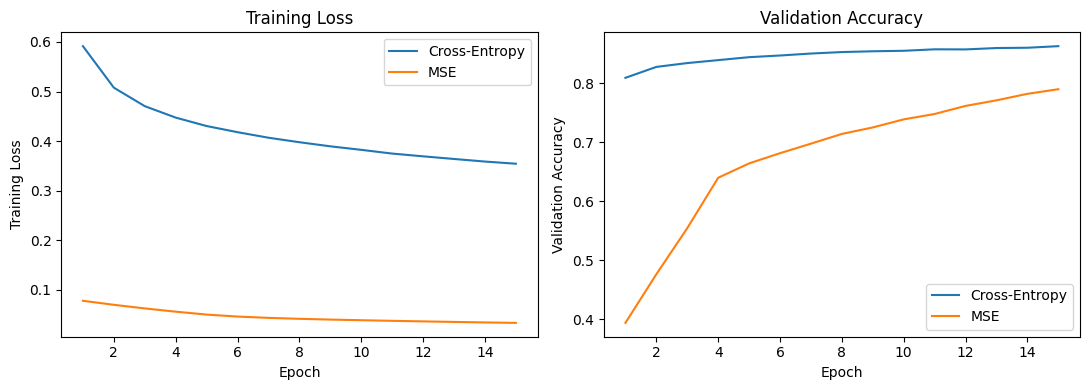

In [ ]:
import matplotlib.pyplot as plt

epochs_ce = [h[0] for h in hist_ce]
loss_ce = [h[1] for h in hist_ce]
acc_ce = [h[2] for h in hist_ce]

epochs_mse = [h[0] for h in hist_mse]
loss_mse = [h[1] for h in hist_mse]
acc_mse = [h[2] for h in hist_mse] # Extract values from training history

fig, axes = plt.subplots(1, 2, figsize=(11, 4)) # Creates 1 row and 2 graphs

axes[0].plot(epochs_ce, loss_ce, label="Cross-Entropy")
axes[0].plot(epochs_mse, loss_mse, label="MSE")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Training Loss")
axes[0].set_title("Training Loss")
axes[0].legend() # Training loss graph

axes[1].plot(epochs_ce, acc_ce, label="Cross-Entropy")
axes[1].plot(epochs_mse, acc_mse, label="MSE")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Validation Accuracy")
axes[1].set_title("Validation Accuracy")
axes[1].legend() # Validation accuracy graph

plt.tight_layout() # Adjusts spacing so graph elements do not overlap
plt.savefig("loss_acc_curves.png", dpi=150) # Saves the two graphs as a PNG image
plt.show()

In [ ]:
ce_test_acc = accuracy(ce_model, X_test, Y_test)
mse_test_acc = accuracy(mse_model, X_test, Y_test)

print("Cross-Entropy Test Accuracy:", ce_test_acc)
print("MSE Test Accuracy:", mse_test_acc)

Cross-Entropy Test Accuracy: 0.8554
MSE Test Accuracy: 0.7755


### Confusion Matrix for Cross Entropy and MSE
The confusion matrix is to see its accuracy on getting the class correct but also which class was the hardest to understand for these models to identify.

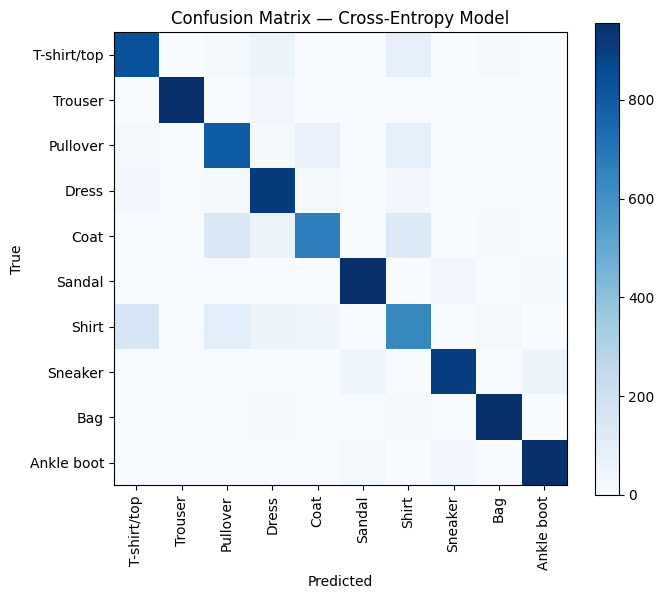

Per-Class CE Accuracy:
T-shirt/top     83.00%
Trouser         95.60%
Pullover        79.50%
Dress           91.20%
Coat            66.30%
Sandal          95.20%
Shirt           63.20%
Sneaker         90.30%
Bag             95.50%
Ankle boot      95.60%


In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
] # 10 class names corresponding to labels 0-9

preds_ce = np.argmax(ce_model.forward(X_test), axis=1) # Collects highest probability class for each image
cm = np.zeros((10, 10), dtype=int) # Confusion matrix:(10, 10)
for true_label, predicted_label in zip(Y_test, preds_ce):
    cm[true_label, predicted_label] += 1 # Add 1 to the cell matching the true and predicted class

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues") # Display the (10, 10) confusion matrix as an image
ax.set_xticks(range(10))
ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(10))
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix — Cross-Entropy Model")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()
per_class_acc = cm.diagonal() / cm.sum(axis=1) # Correct predictions/number of images

print("Per-Class CE Accuracy:")
for name, acc in zip(class_names, per_class_acc): # Pair each class name with its corresponding accuracy
    print(f"{name:15s} {acc:.2%}")

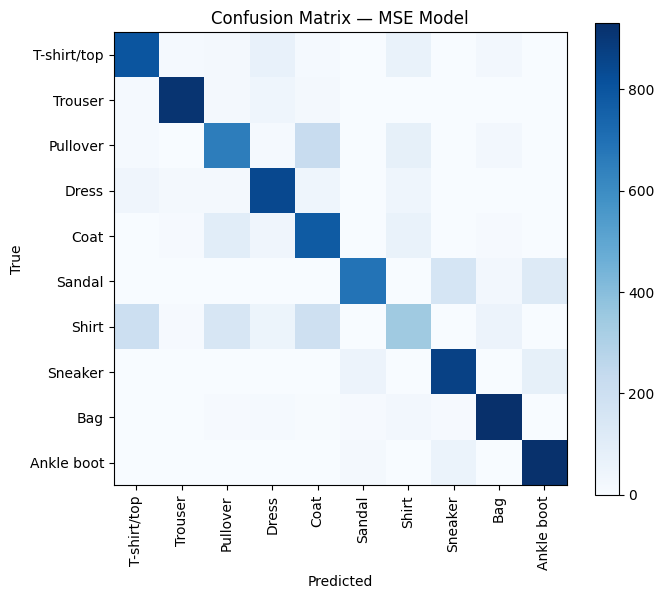

Per-Class MSE Accuracy:
T-shirt/top     79.80%
Trouser         91.50%
Pullover        65.30%
Dress           84.10%
Coat            77.80%
Sandal          68.80%
Shirt           34.30%
Sneaker         86.70%
Bag             93.10%
Ankle boot      92.50%


In [ ]:
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

preds_mse = np.argmax(mse_model.forward(X_test), axis=1)
sm = np.zeros((10, 10), dtype=int)

for true_label, predicted_label in zip(Y_test, preds_mse):
    sm[true_label, predicted_label] += 1

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(sm, cmap="Blues")

ax.set_xticks(range(10))
ax.set_xticklabels(class_names, rotation=90)
ax.set_yticks(range(10))
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
ax.set_title("Confusion Matrix — MSE Model")
plt.colorbar(im)
plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150)
plt.show()

per_class_acc = sm.diagonal() / sm.sum(axis=1)
print("Per-Class MSE Accuracy:")
for name, acc in zip(class_names, per_class_acc):
    print(f"{name:15s} {acc:.2%}")

## Discussion
Both of these models utilised the same MLP structure from the initial weights down to the number of epochs and batch sizes. The only significant difference maker was the loss function during back propogation where this allowed me to see the difference between MSE and cross entropy learning behaviours under the same conditions.

The cross entropy model clearly learned considerably faster compared to MSE after the first epoch. However, by the 15th epoch MSE went from 37.9% to 78.1% whilst cross entropy went from 78.6% to 86.9%. This large gap clearly shows te differing strengths and weaknesses of the two learning behaviours.

####**Why did cross entropy learn faster?**

This is due to how both cross entropy and MSE do their backpropagation. For cross-entropy combined with softmax, the gradient of the loss with respect to the pre-softmax logits is dL/dz=a-y which appears in the code as dZ3 = (self.A3 - y_true)/n under class MLP. A3 contains the probabilities produced after softmax, while dZ3 represents the gradient with respect to the logits before softmax.

Compared to MSE where it is dA3 = 2 * (self.A3 - y_true) / (n*self.A3.shape[1]) and dZ3 = self.A3 * (dA3 - np.sum(dA3 * self.A3, axis=1, keepdims=True)). dA3 is the derivative of the MSE loss with respect to the softmax probabilities. And the division by n x text{self.A3.shape[1]} comes from np.mean(...) averaging over every element of the n, 10 output array. For a batch of 64 images, there are \64 x 10 = 640 values being averaged, so the derivative is divided by 640. Now we do the dZ3 part where The np.sum(...) part accounts for the fact that the softmax outputs are connected and must sum to 1. This is used to adjust the gradient for each output before multiplying by self.A3 to calculate dZ3, the gradient with respect to the logits. dZ3 is then used to calculate the weight gradients, such as dW3, which tell us how the weights should be updated.

Therefore, as displayed by the coding the MSE gradient is affected by the softmax probabilities. Since the softmax output can be small or large this reduces the gradient passing backwards through th enetwork, however, with cross entropy it avoids this additional multiplication in its simplified gradient helping it produce a stronger learning signal initially. This provides a reason to why CE improved so much earlier compared to MSE whilst MSE learnt a lot more over 15 epoch.

####**Loss Values**

The numerical value of MSE is much smaller comparitive to CE the way they are mesaured are completly different. MSE gets the loss value by subtracting the predicting to the true value and then squaring as seen in the def mse_loss. For CE it takes the predicted probability for each class, calculates the log of those probabilities and multiplies them by the true value. Due to this you would get different loss values Thus we ask the question of how do we compare them. This is in the test and validation accuracy which shows the CE model performed much better compared ot MSE in both but in validation we see MSE improve much more compared to CE.

####**The Relationship between Loss Function and the Task**

So the goal of this task is to guess the clothing class correctly for each image. Accuracy measures how many predictions the model gets correct, but it is not used to train the model because argmax is not differentiable. Argmax is used after the model produces its probabilities to select the class with the highest probability. During training, a differentiable loss function such as CE or MSE is used instead. The loss measures how far the model's predictions are from the true labels and provides the gradient information needed for backpropagation and updating the weights. The loss function measures the error and provides the gradient needed to update the weights during backpropagation.

CE is great for an issue like this due to the the network's final softmax layer represents a probability distribution across the ten mutually exclusive classes meaning if the the prediction is highly correct then low loss, but highly wrong loss will be high. MSE however can still train the network as seen by its improvement in the validation accuracy but under the same controlled environment it had learned substanctially slower initially and achieved a lower score.

####**Class Specific Performance**

The confusion matrices were utilised to investigate performance beyond the accuracy to see which classes specifically gave the mot trouble. Each row represented the real answer whist the columns showed the predictions. The values along the principal diagonal represent the correct predictions with values outside of that were misidentified for another.

For the CE model most of the predictions were across the pricipal diagonal indicating a strong performance across most classes except for shirt. 48% of the actual Shirt images were correctly predicted as Shirt. There is also coat with an accuracy of 73% not as bad as the shirt since they mostly mistook it for just a pullover. This shows that the MLP had a great difficulty in identifying clothing characteristics specific for the shirt.

The MSE model showed similar patterns to the CE model confusion matrix, but the erros were much more identifiable in the image. With shirt once again very difficult to identify but at 33% identified correctly, sandal 69%, coat 76%, pullover 67% and T-shirt/top 79%. This could be due to how hard it was to identify specific characteristics for the shirt which is what made everything else bad as seen before in the CE model. Overall though the confusion matrices suppport the accuracy results by showing the CE models produced fewer classification across the test classes.

####**Weaknesses and Possible Improvements**

So the first thing to consider is that this experiment only had a single set up. Even though this helps us identify clearly which model is better when changing the loss function but there is a limitation in that where we haven't changed these different variables. So we can clearly state that when both models use lr=0.01, batch size 64, 15 epochs, and this architecture, CE performs better. However, that doesn't insinuate that CE is actually better than MSE because if the environment was different then the results could have varied quite a bit. Maybe next time we could have differently tuned hyperparameters or more training epochs thus allowing us to see what a tuned CE and a tuned MSE could compare and also the validation accuracy of the MSE was increasing at a much faster rate compared to CE overall. So if there was maybe 30 epochs or 50 epochs MSE could have surpassed CE in accuracy.

The second limitation that we have to consider is the flattening. Since the original datatset is a 28x28 image giving it a spactial structure there would be pixels above it, below it, left and right, however due to my preprocessing X_train_og.reshape(-1, 784)/255. Although the pixel values are normalised from 0–255 to 0–1 before being passed into the network, the model does not explicitly exploit the two-dimensional spatial structure of the image. Perhaps in a future experiment could compare this MLP with a convolutional neural network(CNN) designed to learn local spatial features.

Overall, my experiment shows CE was better than MSE for the specific setup I tested, but I shouldn't claim CE will always be better because I didn't try every possible hyperparameter configuration. My MLP also has an architectural limitation because it flattens images rather than explicitly learning their 2D spatial features. Future experiments could tune the models more extensively and compare the MLP with a CNN.

## Implementation Log

#### **What I tried**

I implemented an MLP(multilayer perceptron) from scratch using NumPy with an architecture 784 -> 128 -> 64 -> 10. The two hidden layers utilise ReLU activiation and the output layer utilises softmax to produce probabilities across the 10 classes. The Fashion MNIST images were flattened from 28x28 to images of 784 dimenional vectors with their pixels normalised from 0-255 to 0-1. I implemented forward pass, backpropagation, CE loss and MSE loss manually. Both of the models were given the exact same architecture with only the losses changed allowing the loss function to be the main variable between the two experiments. I also seperated 6000 images from the training data set to used for validaiton keeping the testing dataset the exact same.

#### **What happened**

The models bot successfullt learned the classification task given but the CE learned much faster than the MSE under the same training where after the first epoch CE achieved 79% whilst MSE had 33%. But however overtime CE reached 87% and MSE 79% showing that MSE's accuracy improved substantially over the later epochs. The confusion matrices also show similar patterns where both models had difficulty in identifying characteristics in similar clothing categories where particularly it was shirt for being the lowest for both where CE had 48% and MSE 33%. The CE model generally though produced fewer classificiation erros across the test classes.

Cross-Entropy Test Accuracy: 0.855
MSE Test Accuracy: 0.7743

#### **What I expected compared to results**

Personally I expected CE to perform substantially better than MSE due to it being better suited to multiclass classification with a softmax output layer. The results supported this expectation, with cross-entropy learning considerably faster and achieving higher validation and test accuracy. However, I did not expect MSE to show such a large improvement in validation accuracy over the 15 epochs, despite its substantially slower initial learning. What was particulary surprising to me was the difference in the early stages where CE was 79% and MSE was 33% but the investigation in the backpropagation explained the reason for this difference. Since with softmax and CE the output gradient simplifies to dZ3 = (self.A3 - y_true)/n whilst the MSE gradient needs to be additionally propagated through the softmax derivative meaning the gradient had to depend on the softmax probabilities producing weaker learning signals under the tested conditions.

#### **AI use and what I need to verify**

I used AI through the development of my project for the initial prototype build which was a lot more complex than what I had initially wanted. Thus being inspired by that I simplified my experiment considerably. I then used AI to help review and debug sections of my NumPy implementation, explain concepts I did not understand, and review my written interpretation of the results. Also rather than accepting the code as it is without any review I did work through the code line by line repeatedly asking questions about the concept I did not understand it utilised.

One remaining knowledge gap I do have still is the understanding of the mathmatical details of backpropagation especially with MSE gradient through the softmax function. Thus before the viva I intend to test my understanding further into the gradient calculations of my experimental result so I can explain it independently.

#### **What I would try next**

! could tune the hyperparameters of cross-entropy and MSE independently rather than requiring both models to use the same learning rate and number of epochs. In particular, MSE could be trained for additional epochs or tested using different learning rates to determine whether some of the observed performance difference was caused by slower optimisation. I would also investigate the architectural limitations of the MLP. Flattening each 28x28 image into 784 features means that the MLP does not explicitly exploit the two-dimensional spatial structure of the images.
